# BAIT 508 Group Project — Part 3: Electronic Arts (EA)
**Step G: firm analysis and strategy suggestion**

**Focal firm:** Electronic Arts Inc. (gvkey 16721, SIC 7372 *prepackaged software*), in the data for all 32 years (1994–2025).

**Direction:** We combine directions 1 and 2 from the brief:
1. **Find EA's competitors** with firm-level word2vec embeddings built from the Part 2 keywords (2025 10-Ks).
2. **Benchmark EA** against those competitors on revenue, market share and ROA.
3. Turn the results into **one suggestion** for EA.

**Inputs from Part 2** (in `output/`): `sector_keywords_2025.csv` (top-10 TF-IDF keywords per firm) and `w2v_2025.bin` (word2vec model trained on all 2025 10-Ks).

*Timing note:* EA's fiscal year ends in March, and Compustat labels a fiscal year ending Jan–May with the previous calendar year. So `fyear 2025` = EA's FY26 (April 2025 – March 2026). Revenue of $7.53B and net income of $887M match EA's reported FY26 results.

*Context:* EA was taken private by a consortium of Saudi Arabia's Public Investment Fund (PIF), Silver Lake and Affinity Partners. The deal closed on 4 August 2026. Our suggestion is therefore addressed to EA's management and its new owners.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from gensim.models import KeyedVectors
from sklearn.metrics.pairwise import cosine_similarity

pd.set_option('display.max_colwidth', 100)

---
## G.1 Who are EA's competitors? (firm embeddings)
**Method** (adapted from the class 08 take-home):
1. Take each firm's **top-10 TF-IDF keywords** from Part 2 (2025). TF-IDF keywords describe what makes a firm *different*, which is what we want when looking for look-alike firms.
2. Look up each keyword's 50-number **word2vec vector** and **add them up**, as the brief asks. This gives one vector per firm, its *firm embedding*.
3. Measure how close every firm is to EA with **cosine similarity** (1 = identical direction).

Adding up the vectors or averaging them (as in class) gives the same cosine similarity, because cosine only looks at the direction of a vector, not its length.

In [2]:
wv = KeyedVectors.load_word2vec_format('output/w2v_2025.bin', binary=True)
kw = pd.read_csv('output/sector_keywords_2025.csv')
print(len(wv), 'words in the word2vec vocabulary |', kw.shape[0], 'Business Services firms')

ea = kw[kw['conm'] == 'ELECTRONIC ARTS INC'].index[0]     # EA's row number
kw.loc[[ea], ['gvkey', 'conm', 'top_keywords_tfidf']]

75384 words in the word2vec vocabulary | 510 Business Services firms


,gvkey,conm,top_keywords_tfidf
166,16721,ELECTRONIC ARTS INC,console games players consoles sports entertainment kelly game football pc


In [3]:
# firm embedding = sum of the word vectors of its keywords
firm_vectors = []
for keywords in kw['top_keywords_tfidf']:
    total = np.zeros(50)
    for w in keywords.split():
        if w in wv:                  # skip the rare keyword the model doesn't know
            total = total + wv[w]
    firm_vectors.append(total)

firm_vectors = np.array(firm_vectors)
firm_vectors.shape

(510, 50)

In [4]:
sims = cosine_similarity(firm_vectors[[ea]], firm_vectors)[0]

peers = pd.DataFrame({'conm': kw['conm'], 'gvkey': kw['gvkey'], 'similarity': sims.round(3),
                      'top_keywords_tfidf': kw['top_keywords_tfidf']})
peers = peers.sort_values('similarity', ascending=False)
peers = peers[peers['conm'] != 'ELECTRONIC ARTS INC']      # drop EA itself
peers.index = range(1, len(peers) + 1)                     # rank 1, 2, 3 ...
peers.head(15)

,conm,gvkey,similarity,top_keywords_tfidf
1,MOTORSPORT GAMES INC,37674,0.949,racing esports games game video console gaming venture nintendo series
2,TAKE-TWO INTERACTIVE SFTWR,64630,0.924,titles xbox games entertainment sony franchises playstation ingame microsoft players
3,SUPER LEAGUE ENTERPRISE INC,34613,0.920,super game league worlds gaming metaverse ingame immersive roblox brands
4,FIRY INC,37562,0.910,game games developers gaming players player skillbased prizes multiplayer bots
5,GAMESQUARE HOLDINGS INC,340388,0.906,esports gaming entertainment games youth audiences believes audience streaming gamers
6,PLAYTIKA HOLDING CORP,37752,0.905,games game gambling casino studios players ingame player monetization virtual
7,HOUSE OF DOGE INC,50435,0.904,house esports gamers tournaments gaming tournament casual tokens membership prizes
8,ZEDGE INC,27318,0.900,app competitions creators paint players sounds game photographs photographers artists
9,VERSUS SYSTEMS INC,140172,0.896,contests games prizes british player columbia rewards players interactive fan
10,TRAVELZOO,149721,0.890,travel club flight jack membership members advertising entertainment advertisers metaverse


### Sanity check: are the matches real competitors?
The embeddings correctly put **gaming companies at the top**. 8 of the 10 closest firms are about games or esports, and Take-Two (EA's most direct rival in console games) ranks #2. But word2vec only reads 10 words per firm, so a few matches are about gaming *language* rather than the gaming *business*.

We read each match's keywords and keep the firms whose main business is **making or running games**:

| Rank | Firm | Keep? | Why |
|---|---|---|---|
| 1 | Motorsport Games | ✅ | racing video games (console/PC) |
| 2 | Take-Two Interactive | ✅ | AAA console/PC publisher (GTA, NBA 2K); closest real rival |
| 3 | Super League Enterprise | ✅ | builds games and branded experiences inside Roblox |
| 4 | Firy Inc | ✅ | skill-based multiplayer mobile games |
| 5 | GameSquare Holdings | ❌ | esports teams and media; doesn't make games |
| 6 | Playtika | ✅ | mobile social-casino and casual games |
| 7 | House of Doge | ❌ | esports tournaments / crypto tokens, no revenue |
| 8 | Zedge | ❌ | ringtone/wallpaper app with mini-competitions |
| 9 | Versus Systems | ❌ | prize/contest technology for other companies |
| 10 | Travelzoo | ❌ | travel deals ("membership", "entertainment" overlap) |
| 11 | Playstudios | ✅ | mobile casual and casino games (just outside the top 10) |

**One big name is missing: Roblox.** Roblox is the fastest-growing gaming company in the sector, but its 10-K calls itself a platform for *"creators"* and *"developers"* rather than a *"games"* company, so its keyword vector points elsewhere. We add it by hand, because no benchmark of EA would be credible without it. Its rank below shows how far the model placed it.

In [5]:
print(peers[peers['conm'] == 'ROBLOX CORP'][['conm', 'similarity', 'top_keywords_tfidf']])

           conm  similarity  \
37  ROBLOX CORP       0.801   

                                                              top_keywords_tfidf  
37  roblox creators developers developer creator immersive 3d client fiat earned  


In [6]:
peer_names = ['TAKE-TWO INTERACTIVE SFTWR', 'ROBLOX CORP', 'PLAYTIKA HOLDING CORP', 'PLAYSTUDIOS INC',
              'FIRY INC', 'MOTORSPORT GAMES INC', 'SUPER LEAGUE ENTERPRISE INC']
group_names = ['ELECTRONIC ARTS INC'] + peer_names
print('Gaming peer group:', len(peer_names), 'competitors + EA')

Gaming peer group: 7 competitors + EA


---
## G.2 Benchmarking EA against its competitors
Financials come from `public_firms.csv` (USD millions). ROA = net income / assets (as in Part 1).

In [7]:
firms = pd.read_csv('data/public_firms.csv')

group_rows = []
for name in firms['conm']:
    group_rows.append(name in group_names)
group = firms[group_rows].copy()
group['roa'] = group['net_income'] / group['asset']
group['net_margin'] = group['net_income'] / group['sale']
print(group.shape)

(110, 14)


### Snapshot: fiscal 2025

In [8]:
g25 = group[group['fyear'] == 2025].copy()
g25['market_share_%'] = g25['sale'] / g25['sale'].sum() * 100
g25['roa_%'] = g25['roa'] * 100
g25['net_margin_%'] = g25['net_margin'] * 100

snapshot = g25[['conm', 'sale', 'net_income', 'asset', 'market_share_%', 'roa_%', 'net_margin_%']]
snapshot = snapshot.sort_values('sale', ascending=False)
snapshot.index = range(1, len(snapshot) + 1)
snapshot.round(1)

,conm,sale,net_income,asset,market_share_%,roa_%,net_margin_%
1,ELECTRONIC ARTS INC,7531.0,887.0,13131.0,33.9,6.8,11.8
2,TAKE-TWO INTERACTIVE SFTWR,6656.4,-298.2,9383.2,30.0,-3.2,-4.5
3,ROBLOX CORP,4890.6,-1065.1,9557.1,22.0,-11.1,-21.8
4,PLAYTIKA HOLDING CORP,2755.4,-206.4,3718.9,12.4,-5.6,-7.5
5,PLAYSTUDIOS INC,235.1,-28.6,290.6,1.1,-9.9,-12.2
6,FIRY INC,104.5,-70.4,293.5,0.5,-24.0,-67.4
7,MOTORSPORT GAMES INC,11.6,6.9,12.0,0.1,57.9,59.7
8,SUPER LEAGUE ENTERPRISE INC,11.3,-20.7,21.9,0.1,-94.7,-182.7


In [9]:
# 5-year revenue growth: compound annual growth rate (CAGR), fiscal 2020 -> 2025
growth = []
for name in group_names:
    s20 = group[(group['conm'] == name) & (group['fyear'] == 2020)]['sale'].values[0]
    s25 = group[(group['conm'] == name) & (group['fyear'] == 2025)]['sale'].values[0]
    cagr = ((s25 / s20) ** (1 / 5) - 1) * 100
    growth.append([name, s20, s25, round(cagr, 1)])

growth = pd.DataFrame(growth, columns=['conm', 'sale_2020', 'sale_2025', 'revenue_CAGR_%'])
growth.sort_values('revenue_CAGR_%', ascending=False)

,conm,sale_2020,sale_2025,revenue_CAGR_%
7,SUPER LEAGUE ENTERPRISE INC,2.064,11.342,40.6
2,ROBLOX CORP,923.885,4890.551,39.6
1,TAKE-TWO INTERACTIVE SFTWR,3372.772,6656.400,14.6
0,ELECTRONIC ARTS INC,5629.000,7531.000,6.0
3,PLAYTIKA HOLDING CORP,2371.500,2755.400,3.0
4,PLAYSTUDIOS INC,269.882,235.097,-2.7
6,MOTORSPORT GAMES INC,19.046,11.606,-9.4
5,FIRY INC,230.115,104.496,-14.6


In [10]:
# 5-year average ROA (fiscal 2021-2025), to smooth out one-off years
recent = group[group['fyear'] >= 2021]
avg_roa = (recent.groupby('conm')['roa'].mean() * 100).round(1).sort_values(ascending=False)
avg_roa

conm
ELECTRONIC ARTS INC              7.4
PLAYTIKA HOLDING CORP            5.5
PLAYSTUDIOS INC                 -5.2
ROBLOX CORP                    -14.2
TAKE-TWO INTERACTIVE SFTWR     -16.7
FIRY INC                       -30.1
MOTORSPORT GAMES INC           -75.1
SUPER LEAGUE ENTERPRISE INC   -132.2
Name: roa, dtype: float64

**The four large players** (EA, Take-Two, Roblox, Playtika) account for about 98% of the group's revenue, so the charts focus on them. The four small firms are combined as *"Small peers (4)"*. Their ROA numbers (from +58% to −95%) come from tiny asset bases and would distort the chart.

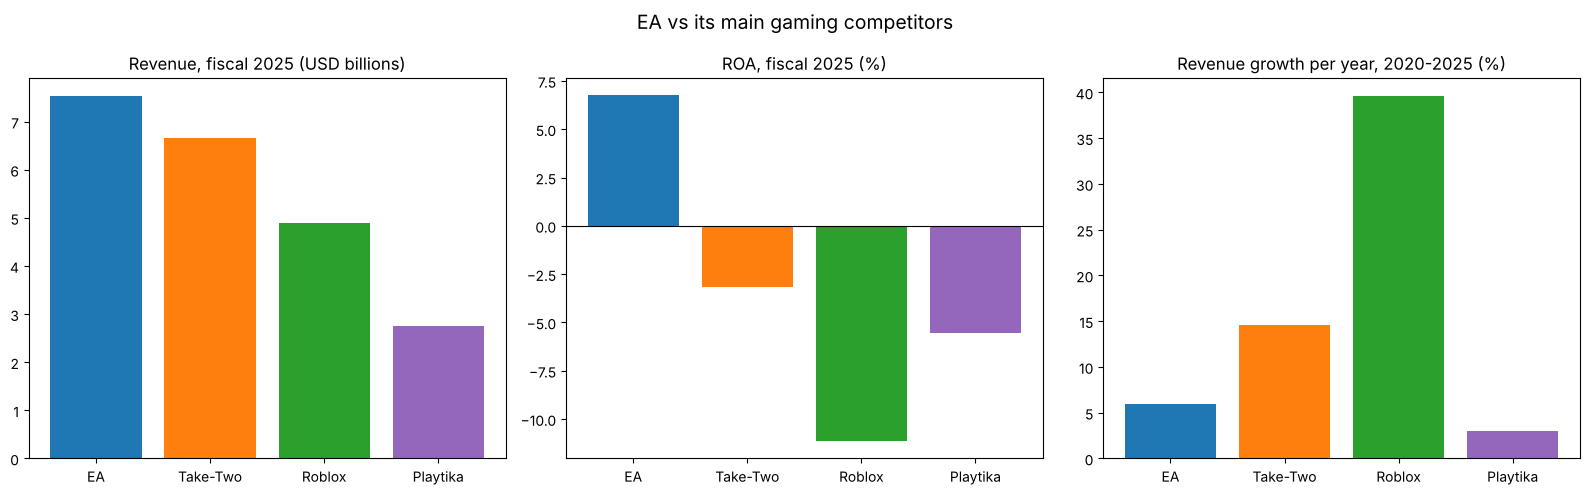

In [11]:
majors = ['ELECTRONIC ARTS INC', 'TAKE-TWO INTERACTIVE SFTWR', 'ROBLOX CORP', 'PLAYTIKA HOLDING CORP']
labels = {'ELECTRONIC ARTS INC': 'EA', 'TAKE-TWO INTERACTIVE SFTWR': 'Take-Two',
          'ROBLOX CORP': 'Roblox', 'PLAYTIKA HOLDING CORP': 'Playtika'}
colors = {'EA': 'tab:blue', 'Take-Two': 'tab:orange', 'Roblox': 'tab:green',
          'Playtika': 'tab:purple', 'Small peers (4)': 'tab:gray'}

major25 = g25[g25['conm'].isin(majors)].copy()            # NEW: isin (keep rows whose name is in the list)
major25['label'] = major25['conm'].map(labels)            # NEW: map (swap long names for short labels)
major25 = major25.sort_values('sale', ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
bar_colors = [colors[l] for l in major25['label']]

axes[0].bar(major25['label'], major25['sale'] / 1000, color=bar_colors)
axes[0].set_title('Revenue, fiscal 2025 (USD billions)')

axes[1].bar(major25['label'], major25['roa_%'], color=bar_colors)
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set_title('ROA, fiscal 2025 (%)')

cagr_major = growth[growth['conm'].isin(majors)].copy()
cagr_major['label'] = cagr_major['conm'].map(labels)
cagr_major = cagr_major.set_index('label').loc[major25['label']]     # same order as the other panels
axes[2].bar(cagr_major.index, cagr_major['revenue_CAGR_%'], color=bar_colors)
axes[2].set_title('Revenue growth per year, 2020-2025 (%)')

plt.suptitle('EA vs its main gaming competitors', fontsize=14)
plt.tight_layout()
plt.savefig('output/G_ea_vs_peers_2025.png', dpi=200, bbox_inches='tight')
plt.show()

### Market share over time (share of the peer group's revenue)
Shown from fiscal 2019, the first year all eight firms have data.

In [12]:
share = group[group['fyear'] >= 2019].copy()
share['label'] = share['conm'].map(labels).fillna('Small peers (4)')     # NEW: fillna (small firms get one shared label)

share_table = share.groupby(['fyear', 'label'])['sale'].sum().unstack()     # NEW: unstack (one column per firm)
share_table = share_table.div(share_table.sum(axis=1), axis=0) * 100         # NEW: each row now sums to 100%
share_table = share_table[['EA', 'Take-Two', 'Roblox', 'Playtika', 'Small peers (4)']]
share_table.round(1)

label,EA,Take-Two,Roblox,Playtika,Small peers (4)
fyear,,,,,
2019,49.7,27.7,4.6,16.9,1.2
2020,43.9,26.3,7.2,18.5,4.1
2021,44.5,22.3,12.2,16.5,4.4
2022,40.8,29.4,12.2,14.4,3.2
2023,40.3,28.5,14.9,13.7,2.6
2024,38.0,28.7,18.3,13.0,2.1
2025,33.9,30.0,22.0,12.4,1.6


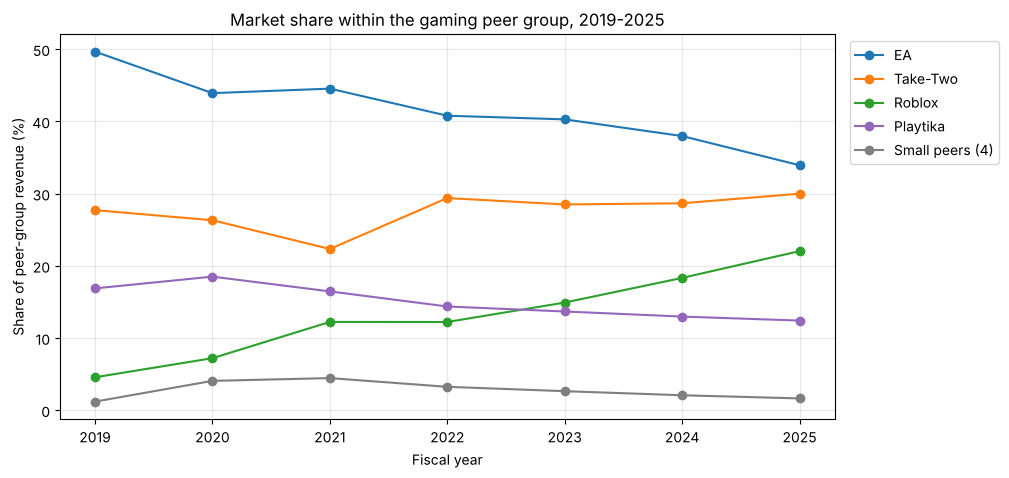

In [13]:
plt.figure(figsize=(10, 5))
for col in share_table.columns:
    plt.plot(share_table.index, share_table[col], marker='o', label=col, color=colors[col])
plt.xlabel('Fiscal year')
plt.ylabel('Share of peer-group revenue (%)')
plt.title('Market share within the gaming peer group, 2019-2025')
plt.legend(loc='upper left', bbox_to_anchor=(1.01, 1))     # legend outside the plot so it doesn't cover EA's line
plt.grid(alpha=0.3)
plt.savefig('output/G_market_share.png', dpi=200, bbox_inches='tight')
plt.show()

### EA's own trend: revenue, profit and ROA (fiscal 2015–2025)

In [14]:
ea_hist = group[(group['conm'] == 'ELECTRONIC ARTS INC') & (group['fyear'] >= 2015)]
ea_hist[['fyear', 'sale', 'net_income', 'asset', 'prcc_c', 'roa']].round(3)

,fyear,sale,net_income,asset,prcc_c,roa
68016,2015,4396.0,1156.0,7050.0,68.72,0.164
68017,2016,4845.0,967.0,7718.0,78.76,0.125
68018,2017,5150.0,1043.0,8584.0,105.06,0.122
68019,2018,4950.0,1019.0,8957.0,78.91,0.114
68020,2019,5537.0,3039.0,11112.0,107.51,0.273
68021,2020,5629.0,837.0,13288.0,143.60,0.063
68022,2021,6991.0,789.0,13800.0,131.90,0.057
68023,2022,7426.0,802.0,13459.0,122.18,0.060
68024,2023,7562.0,1273.0,13420.0,136.81,0.095
68025,2024,7463.0,1121.0,12368.0,146.30,0.091


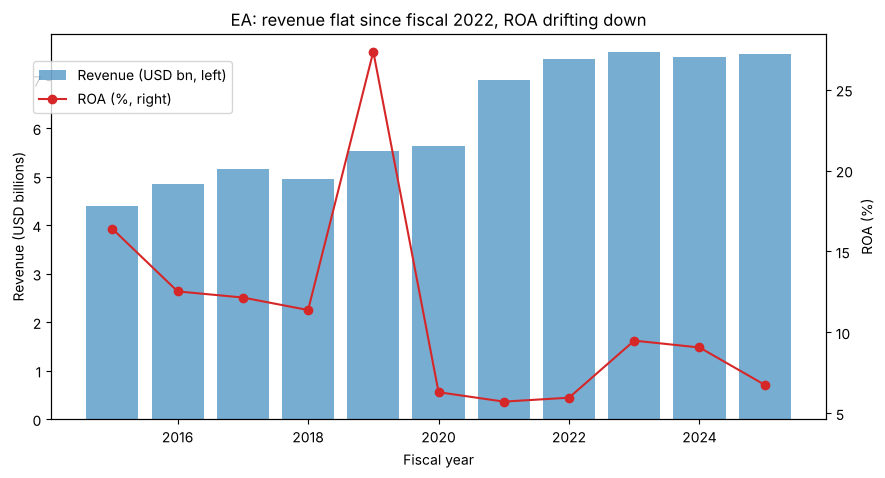

In [15]:
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.bar(ea_hist['fyear'], ea_hist['sale'] / 1000, color='tab:blue', alpha=0.6, label='Revenue (USD bn, left)')
ax1.set_xlabel('Fiscal year')
ax1.set_ylabel('Revenue (USD billions)')

ax2 = ax1.twinx()                                       # NEW: a second y-axis on the right
ax2.plot(ea_hist['fyear'], ea_hist['roa'] * 100, color='tab:red', marker='o', label='ROA (%, right)')
ax2.set_ylabel('ROA (%)')

fig.legend(loc='upper left', bbox_to_anchor=(0.1, 0.84))
plt.title('EA: revenue flat since fiscal 2022, ROA drifting down')
plt.savefig('output/G_ea_trend.png', dpi=200, bbox_inches='tight')
plt.show()

*Fiscal 2019 ROA (27%) is a one-off: that year's net income ($3.0B) included a large tax benefit, not operating profit.*

### What the benchmarks say
1. **EA is the biggest and the only consistently profitable major.** EA has the highest fiscal-2025 revenue ($7.53B, **34% of the peer group**) and is the only one of the four large players that made money: ROA **6.8%** vs Take-Two −3.2%, Playtika −5.6% and Roblox −11.1%. Its 5-year average ROA (7.4%) is the best in the group.
2. **But EA is steadily losing market share.** EA's share of peer-group revenue fell from **49.7% (2019) to 33.9% (2025)**, down every year since 2021. Almost all of it went to **Roblox (4.6% → 22.0%)**. Take-Two held roughly steady at 28–30%, helped by buying the mobile publisher Zynga in 2022.
3. **EA is growing slowest among the big players.** Revenue grew **6.0% a year** from 2020 to 2025, vs 14.6% for Take-Two and **39.6% for Roblox**. EA's revenue has been flat at about $7.4–7.6B for four straight years (fiscal 2022–2025).
4. **EA's returns are slipping.** ROA was 11–16% in 2015–2018 but only about 6–10% since 2020. Assets nearly doubled ($7.1B → $13.1B), partly from EA's 2021 acquisitions (Codemasters, Glu Mobile, Playdemic), while profit stayed around $0.8–1.3B.
5. **The text points to the same gap.** EA's 2025 keywords (*console, games, players, sports, football, pc*) describe a company built on console releases and licensed sports. Roblox describes itself through *creators, developers, immersive, 3d*. Its business model is so different that the embedding model ranked it only #37 for similarity to EA, even though it is the main firm taking EA's share.

**Bottom line:** EA is profitable but has stopped growing, and it is losing share to a platform where players and creators make the content.

---
## G.3 Suggestion for EA
### Turn EA's biggest owned franchises into creator platforms

**Suggestion:** Give players and independent creators official tools to **build and sell their own content inside EA's games**, with a **revenue share**, the way Roblox does. Start with franchises EA fully owns: **The Sims, Battlefield and Apex Legends**.

**Why: what the analysis shows**
- **EA's lost share went to a creator platform.** EA's share of peer-group revenue fell **16 points (49.7% → 33.9%)** from 2019 to 2025, while Roblox gained **17 points (4.6% → 22.0%)**. Take-Two, the traditional publisher, held steady. Players aren't leaving games; they're moving to games other players build.
- **EA has the strongest gaming franchises but has stopped growing.** Revenue has been flat at about $7.5B for four years, and growth (6%/yr) trails Roblox (40%) and Take-Two (15%). Selling more copies of the same annual releases is not moving the numbers.
- **EA can afford it, and its rivals can't.** EA is the only profitable major (ROA 6.8% vs Roblox −11.1%). Its new private owners (PIF, Silver Lake, Affinity Partners) can fund a multi-year build without quarterly market pressure.
- **The text analysis points the same way.** The embeddings placed Roblox only #37 for similarity to EA. EA describes itself through *console, sports, players*; Roblox through *creators, developers*. EA lacks exactly the business model that is growing. Part 2 also showed *ai* and *generative* spreading fast across the sector (AI mentioned by 18% → 65% of firms), and generative-AI tools make it much easier for ordinary players to build content.

**How:**
1. **Year 1: build on what exists.** Expand Battlefield's *Portal* custom-game builder and give The Sims' already huge custom-content community official tools and a marketplace.
2. **Year 2: pay creators.** Revenue share on creator-made items and modes, plus discovery tools that send players to the best creations.
3. **Year 3: spread it across the portfolio.** Shared creator tools (with AI assistance) across EA's owned games.

**How to measure success:** share of player hours spent in creator-made content, total creator payouts, EA's peer-group revenue share back above **35%**, and revenue growth back above **10% a year**.

**Risks and how to manage them:**
- **Profitability:** Roblox's model loses money. EA should keep a **higher platform cut** and build on existing hit games instead of a new platform from scratch.
- **Licensing:** sports titles (EA Sports FC, Madden) rely on league and player licences that limit what creators can do with them. That is why the plan **starts with owned IP**.
- **Brand safety:** creator content needs moderation, especially for the younger Sims audience.

---
**References / AI disclosure:** Firm-embedding method adapted from the BAIT 508 class 08 take-home (word2vec firm vectors and cosine similarity). EA deal context: PIF press release, *"Electronic Arts announces completion of acquisition by PIF, Silver Lake, and Affinity Partners"* (Aug 2026). EA FY26 results: EA Q4 FY26 earnings release. Claude (Anthropic) was used to help draft and structure this notebook; all outputs were run and checked by the team.